## Data View

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path("/home/ec2-user/studies/HUIFA-RNA-SEQ-new/Project/2026-nc-final").resolve()
DATASETS_DIR = (Path("/home/ec2-user/studies") / "hpp_datasets").resolve()

sys.path.append(str(PROJECT_DIR))

from phenokit.preprocessing.qc import MissingValueAnalyzer
from phenokit.preprocessing.io import read_parquet

In [5]:
pfile = f'{DATASETS_DIR}/oral_microbiome/oral_microbiome.parquet'
df_oral = read_parquet(pfile)
print(df_oral.shape)
df_oral.head()

(8816, 41)


,participant_id,cohort,research_stage,array_index,collection_date,raw_read_count,non_human_read_count,trimmed_non_human_read_count,metaphlan4_aligned_read_count,gene_aligned_read_count,...,humann_aggregated_pathway_coverage_pathway_level_arrow,humann_aggregated_pathway_coverage_microbiome_level_arrow,metaphlan_abundance_kingdom_parquet,metaphlan_abundance_phylum_parquet,metaphlan_abundance_class_parquet,metaphlan_abundance_order_parquet,metaphlan_abundance_family_parquet,metaphlan_abundance_genus_parquet,metaphlan_abundance_species_parquet,metaphlan_abundance_strain_parquet
0,2019372998,10k,00_00_visit,0,2019-03-11,37916332,4868595,4434660,168549,3083959,...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/metaphlan_abundances_aggregated/k...,./aggregated/metaphlan_abundances_aggregated/p...,./aggregated/metaphlan_abundances_aggregated/c...,./aggregated/metaphlan_abundances_aggregated/o...,./aggregated/metaphlan_abundances_aggregated/f...,./aggregated/metaphlan_abundances_aggregated/g...,./aggregated/metaphlan_abundances_aggregated/s...,./aggregated/metaphlan_abundances_aggregated/s...
1,1345092356,10k,00_00_visit,0,2019-03-11,44318839,972926,861009,24539,272374,...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/metaphlan_abundances_aggregated/k...,./aggregated/metaphlan_abundances_aggregated/p...,./aggregated/metaphlan_abundances_aggregated/c...,./aggregated/metaphlan_abundances_aggregated/o...,./aggregated/metaphlan_abundances_aggregated/f...,./aggregated/metaphlan_abundances_aggregated/g...,./aggregated/metaphlan_abundances_aggregated/s...,./aggregated/metaphlan_abundances_aggregated/s...
2,7287081187,10k,00_00_visit,0,2019-03-11,27446983,955728,844364,28825,301503,...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/metaphlan_abundances_aggregated/k...,./aggregated/metaphlan_abundances_aggregated/p...,./aggregated/metaphlan_abundances_aggregated/c...,./aggregated/metaphlan_abundances_aggregated/o...,./aggregated/metaphlan_abundances_aggregated/f...,./aggregated/metaphlan_abundances_aggregated/g...,./aggregated/metaphlan_abundances_aggregated/s...,./aggregated/metaphlan_abundances_aggregated/s...
3,1956245477,10k,00_00_visit,0,2019-03-11,29097776,2552417,2305465,57928,601784,...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/metaphlan_abundances_aggregated/k...,./aggregated/metaphlan_abundances_aggregated/p...,./aggregated/metaphlan_abundances_aggregated/c...,./aggregated/metaphlan_abundances_aggregated/o...,./aggregated/metaphlan_abundances_aggregated/f...,./aggregated/metaphlan_abundances_aggregated/g...,./aggregated/metaphlan_abundances_aggregated/s...,./aggregated/metaphlan_abundances_aggregated/s...
4,2660358136,10k,00_00_visit,0,2019-03-11,31833260,6505711,5945735,183628,1786778,...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/humann_aggregated/pathway_coverag...,./aggregated/metaphlan_abundances_aggregated/k...,./aggregated/metaphlan_abundances_aggregated/p...,./aggregated/metaphlan_abundances_aggregated/c...,./aggregated/metaphlan_abundances_aggregated/o...,./aggregated/metaphlan_abundances_aggregated/f...,./aggregated/metaphlan_abundances_aggregated/g...,./aggregated/metaphlan_abundances_aggregated/s...,./aggregated/metaphlan_abundances_aggregated/s...


In [3]:
pfile = f'{DATASETS_DIR}/oral_microbiome/aggregated/metaphlan_abundances_aggregated/species.parquet'
df_oral_metap_species = read_parquet(pfile)
print(df_oral_metap_species.shape)
df_oral_metap_species.head()

(8834, 742)


#clade_name,participant_id,cohort,research_stage,array_index,collection_date,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinobaculum|s__Actinobaculum_sp_oral_taxon_183,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_SGB15893,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_SGB17154,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_SGB17168,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_bouchesdurhonensis,...,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Yersiniaceae|g__Serratia|s__Serratia_ficaria,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pseudomonadales|f__Moraxellaceae|g__Acinetobacter|s__Acinetobacter_baylyi,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pseudomonadales|f__Pseudomonadaceae|g__Pseudomonas|s__Pseudomonas_lundensis,k__Bacteria|p__Spirochaetes|c__Spirochaetia|o__Spirochaetales|f__Spirochaetaceae|g__Treponema|s__Treponema_putidum,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Micrococcales|f__Intrasporangiaceae|g__Janibacter|s__Janibacter_indicus,k__Bacteria|p__Bacteroidetes|c__Flavobacteriia|o__Flavobacteriales|f__Weeksellaceae|g__Chryseobacterium|s__Chryseobacterium_daecheongense,k__Bacteria|p__Proteobacteria|c__Betaproteobacteria|o__Burkholderiales|f__Alcaligenaceae|g__Achromobacter|s__Achromobacter_marplatensis,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Enterobacterales|f__Erwiniaceae|g__Pantoea|s__Pantoea_ananatis,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Xanthomonadales|f__Xanthomonadaceae|g__Pseudoxanthomonas|s__Pseudoxanthomonas_sp_NML171200,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Xanthomonadales|f__Xanthomonadaceae|g__Stenotrophomonas|s__Stenotrophomonas_acidaminiphila
0,1016331244,10k,undefined,0,2019-09-16,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1033161300,10k,undefined,0,2020-01-02,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1041888957,10k,undefined,0,2019-11-01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1046910620,10k,undefined,0,2019-11-01,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1063317644,10k,undefined,0,2020-01-02,1.23557,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# 从 df2 取映射关系（去重避免重复匹配）
stage_map = df_oral[['participant_id', 'collection_date', 'research_stage']].drop_duplicates()

# 合并
df_oral_metap_species_filled = df_oral_metap_species.merge(
    stage_map,
    on=['participant_id', 'collection_date'],
    how='left',
    suffixes=('_old', '')
)

# 用 df2 的值填充，删掉旧列
df_oral_metap_species_filled['research_stage'] = df_oral_metap_species_filled['research_stage'].fillna(
    df_oral_metap_species_filled['research_stage_old']
)
df_oral_metap_species_filled.drop(columns=['research_stage_old'], inplace=True)

In [7]:
df_oral_metap_species = df_oral_metap_species_filled

Overall missing rate: 0.9502 (6228174 out of 6554828)
=== Feature missing-rate report. (Top 10) ===
                                                    missing_rate  \
k__Bacteria|p__Actinobacteria|c__Actinobacteria...      0.999887   
k__Bacteria|p__Proteobacteria|c__Gammaproteobac...      0.999887   
k__Bacteria|p__Proteobacteria|c__Gammaproteobac...      0.999887   
k__Bacteria|p__Proteobacteria|c__Gammaproteobac...      0.999887   
k__Bacteria|p__Actinobacteria|c__Actinobacteria...      0.999887   
k__Eukaryota|p__Ascomycota|c__Eurotiomycetes|o_...      0.999887   
k__Bacteria|p__Proteobacteria|c__Gammaproteobac...      0.999887   
k__Bacteria|p__Proteobacteria|c__Gammaproteobac...      0.999887   
k__Bacteria|p__Proteobacteria|c__Gammaproteobac...      0.999887   
k__Bacteria|p__Proteobacteria|c__Deltaproteobac...      0.999887   

                                                    missing_count  
k__Bacteria|p__Actinobacteria|c__Actinobacteria...           8833  
k__Bacteria|p__

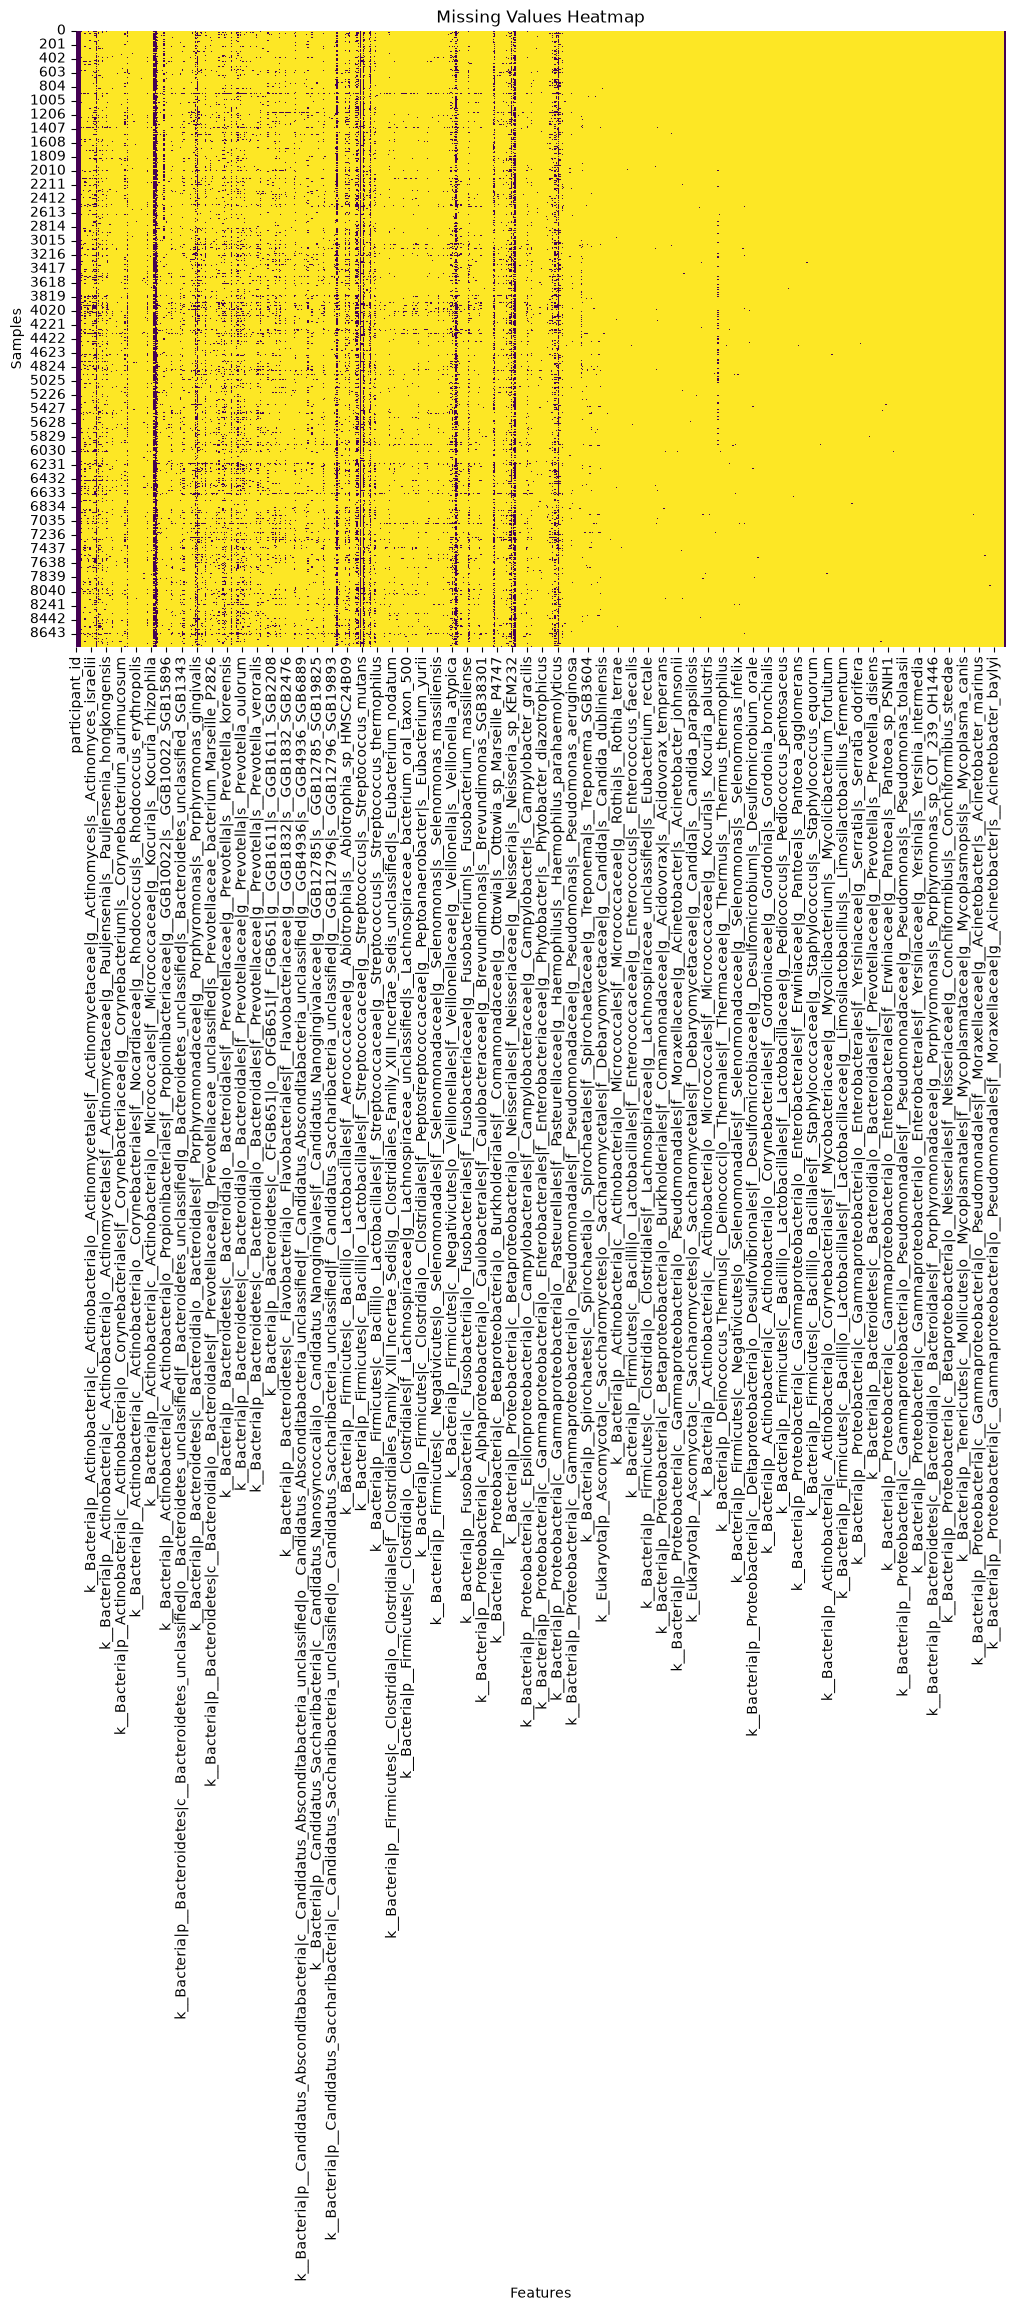

In [8]:
# Check the number and proportion of missing values
missing_analyzer = MissingValueAnalyzer(df_oral_metap_species)
missing_analyzer.overall_missing_rate()
missing_analyzer.report_features()
missing_analyzer.report_samples()
missing_analyzer.report_heatmap()

In [9]:
oral_metadata_col = ['participant_id', 'cohort', 'research_stage', 'array_index', 'collection_date', 'collection_timestamp', 'timezone']
oral_metadata_col = [col for col in oral_metadata_col if col in df_oral_metap_species.columns]
df_oral_metadata = df_oral_metap_species[oral_metadata_col]
df_oral_features = df_oral_metap_species.drop(columns=oral_metadata_col)

## Imputation

In [10]:
impute_value = 0
min_samples = 500

# detected = (df_gut_urs_features > 0) # 0 和 nan 为 false
detected = ~df_oral_features.isna() # nan 为 false，0 视为有意义值
detected_counts = detected.sum(axis=0)  # 每列（物种）被检测到的样本数
keep_species = detected_counts[detected_counts >= min_samples].index
df_oral_features_filtered = df_oral_features.loc[:, keep_species].copy()

df_oral_features_imputed = df_oral_features_filtered.fillna(impute_value)
print(df_oral_features_imputed.shape)
df_oral_features_imputed.head()

(8834, 122)


,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinobaculum|s__Actinobaculum_sp_oral_taxon_183,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_SGB17168,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_dentalis,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_gerencseriae,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_graevenitzii,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_johnsonii,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_massiliensis,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_naeslundii,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_oris,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_sp_ICM47,...,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Aggregatibacter|s__Aggregatibacter_segnis,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Aggregatibacter|s__Aggregatibacter_sp_oral_taxon_458,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_haemolyticus,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_influenzae,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_parahaemolyticus,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_parainfluenzae,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_paraphrohaemolyticus,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_sputorum,k__Bacteria|p__Proteobacteria|c__Oligoflexia|o__Bdellovibrionales|f__Bdellovibrionales_unclassified|g__Bdellovibrionales_unclassified|s__Bdellovibrionales_bacterium,k__Bacteria|p__Bacteroidetes|c__Chitinophagia|o__Chitinophagales|f__Chitinophagaceae|g__Hydrobacter|s__Hydrobacter_penzbergensis
0,0.00000,0.0,0.0,0.0,0.0,0.00000,0.00000,0.00000,0.36880,0.00000,...,0.64691,0.00000,0.00000,0.27723,1.17975,3.43589,0.0,0.0,0.0,0.0
1,0.00000,0.0,0.0,0.0,0.0,0.00000,0.31114,0.00000,4.64503,0.33383,...,0.00000,0.14584,0.18968,0.00000,0.00000,0.20933,0.0,0.0,0.0,0.0
2,0.00000,0.0,0.0,0.0,0.0,0.00000,0.00000,0.00000,0.00000,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0
3,0.00000,0.0,0.0,0.0,0.0,0.00000,0.00000,0.00000,1.86853,0.00000,...,0.00000,3.03487,1.24983,0.00000,0.00000,16.58079,0.0,0.0,0.0,0.0
4,1.23557,0.0,0.0,0.0,0.0,0.05413,0.00000,0.15453,2.21519,0.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.17202,0.0,0.0,0.0,0.0


## Save

In [11]:
df_oral_metadata.reset_index(drop=True, inplace=True)
df_oral_features_imputed.reset_index(drop=True, inplace=True)
df_oral = pd.concat([df_oral_metadata, df_oral_features_imputed], axis=1)
pfile = 'processed_data/070-oral_microbiome_imputed.parquet'
df_oral.to_parquet(pfile, index=False)

In [12]:
pfile = 'processed_data/070-oral_microbiome_imputed.parquet'
df_oral = pd.read_parquet(pfile)
print(df_oral.shape)
df_oral.head()

(8834, 127)


,participant_id,cohort,research_stage,array_index,collection_date,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinobaculum|s__Actinobaculum_sp_oral_taxon_183,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_SGB17168,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_dentalis,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_gerencseriae,k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces|s__Actinomyces_graevenitzii,...,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Aggregatibacter|s__Aggregatibacter_segnis,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Aggregatibacter|s__Aggregatibacter_sp_oral_taxon_458,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_haemolyticus,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_influenzae,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_parahaemolyticus,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_parainfluenzae,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_paraphrohaemolyticus,k__Bacteria|p__Proteobacteria|c__Gammaproteobacteria|o__Pasteurellales|f__Pasteurellaceae|g__Haemophilus|s__Haemophilus_sputorum,k__Bacteria|p__Proteobacteria|c__Oligoflexia|o__Bdellovibrionales|f__Bdellovibrionales_unclassified|g__Bdellovibrionales_unclassified|s__Bdellovibrionales_bacterium,k__Bacteria|p__Bacteroidetes|c__Chitinophagia|o__Chitinophagales|f__Chitinophagaceae|g__Hydrobacter|s__Hydrobacter_penzbergensis
0,1016331244,10k,00_00_visit,0,2019-09-16,0.00000,0.0,0.0,0.0,0.0,...,0.64691,0.00000,0.00000,0.27723,1.17975,3.43589,0.0,0.0,0.0,0.0
1,1033161300,10k,00_00_visit,0,2020-01-02,0.00000,0.0,0.0,0.0,0.0,...,0.00000,0.14584,0.18968,0.00000,0.00000,0.20933,0.0,0.0,0.0,0.0
2,1041888957,10k,00_00_visit,0,2019-11-01,0.00000,0.0,0.0,0.0,0.0,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.0,0.0,0.0,0.0
3,1046910620,10k,00_00_visit,0,2019-11-01,0.00000,0.0,0.0,0.0,0.0,...,0.00000,3.03487,1.24983,0.00000,0.00000,16.58079,0.0,0.0,0.0,0.0
4,1063317644,10k,00_00_visit,0,2020-01-02,1.23557,0.0,0.0,0.0,0.0,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.17202,0.0,0.0,0.0,0.0
